In [1]:
import os
import pickle
import sys
import threading
import time
import traceback

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, SymLogNorm
from joblib import Parallel, delayed, parallel_config

root_dir = os.path.abspath("..")
os.environ["PYTHONPATH"] = root_dir + os.pathsep + os.environ.get("PYTHONPATH", "")
data_dir = os.path.join(root_dir, "data")
figs_dir = os.path.join(root_dir, "figs")
os.makedirs(data_dir, exist_ok=True)
if root_dir not in sys.path:
    sys.path.append(root_dir)

from current_setpoints.models.machines import ieee_machine2_trained_neural_flux_and_torque
from current_setpoints.models.forward_model import ForwardModel, Fault, count_peaks_at_limit
from current_setpoints.optimization import StaticOptimizer, ActiveSetOptimizer, calculate_grid, grid_to_data
from current_setpoints.utils.plotting import plot_grid_segments, PlotConfig


def call_with_timeout(timeout, fn, *args, **kwargs):
    """Plain daemon thread, same mechanism as grid.py's _call_with_timeout."""
    result = {}

    def _run():
        try:
            result["value"] = fn(*args, **kwargs)
        except Exception as exc:
            result["error"] = exc

    t = threading.Thread(target=_run, daemon=True)
    t.start()
    t.join(timeout)
    if t.is_alive():
        return None, "timeout"
    if "error" in result:
        return None, f"exception: {result['error']!r}"
    return result.get("value"), None

In [2]:
QUICK = os.environ.get("MAP_QUICK") == "1"

CURR_MAX = 30.0
VOLT_MAX = 13.0
OMEGA_MAX = 1800.0
SLSQP_OPTS = {"disp": False, "ftol": 1e-8, "maxiter": 500}
N_GRID = 30 if QUICK else 60
PROBE_TIMEOUT_SECONDS = 2400
CELL_TIMEOUT_SECONDS = 900
SAVE_POINT_PNGS = not QUICK

FULL_N = 23
COARSE_TOP, TORQ_TOP = 0.8, 1.02
_n_coarse = round(FULL_N * 9 / 25)
FULL_FRAC = np.concatenate([np.linspace(0.0, COARSE_TOP, _n_coarse),
                            COARSE_TOP + (TORQ_TOP - COARSE_TOP) * np.arange(1, FULL_N - _n_coarse + 1) / (FULL_N - _n_coarse)])
SPEED_IDX = [0, 11, 22] if QUICK else [0, 5, 10, 12, 14, 16, 17, 18, 20, 22]
ROW_IDX = [0, 11, 20] if QUICK else [0, 2, 4, 6, 7, 10, 13, 16, 18, 20, 21, 22]

VARIANTS = {"fix": 0.0, "band": 0.02}
VARIANT_TAGS = {"fix": "fix", "band": "fix_band2"}
CASES = {"healthy": (), "one_fault": (0,), "two_adjacent": (0, 1), "two_nonadjacent": (0, 2)}
CASE_TITLES = {"healthy": "healthy", "one_fault": "phase a open", "two_adjacent": "phases a, b open",
               "two_nonadjacent": "phases a, c open"}
FAULTS = [c for c in CASES if CASES[c]]

MODEL_TAG = "tauR"
N_TORQ, N_OMEGA = len(ROW_IDX), len(SPEED_IDX)
run_tags = {v: f"{N_TORQ}x{N_OMEGA}_N{N_GRID}_{MODEL_TAG}_{VARIANT_TAGS[v]}" + ("_quick" if QUICK else "") for v in VARIANTS}
LEGACY_TAG = f"{FULL_N}x{FULL_N}_N60_{MODEL_TAG}"

drive = ieee_machine2_trained_neural_flux_and_torque(curr_max=CURR_MAX, volt_max=VOLT_MAX)
const_mech_speed = 30.0 / (np.pi * drive.n_ppairs)
dim = drive.dim
vec_omega = np.linspace(0.0, OMEGA_MAX, FULL_N)[SPEED_IDX] / const_mech_speed
rpm_vec = vec_omega * const_mech_speed
frac = FULL_FRAC[ROW_IDX]
print(f"model {MODEL_TAG}, N_GRID={N_GRID}, grid {N_TORQ} torques x {N_OMEGA} speeds, run tags {run_tags}")
print("speeds [rpm]:", " ".join(f"{r:.0f}" for r in rpm_vec))
print("torque fractions:", " ".join(f"{f:.3f}" for f in frac))

model tauR, N_GRID=60, grid 12 torques x 10 speeds, run tags {'fix': '12x10_N60_tauR_fix', 'band': '12x10_N60_tauR_fix_band2'}
speeds [rpm]: 0 409 818 982 1145 1309 1391 1473 1636 1800
torque fractions: 0.000 0.229 0.457 0.686 0.800 0.844 0.888 0.932 0.961 0.991 1.005 1.020


In [3]:
PHASE_LETTERS = ["a", "b", "c", "d", "e"]


def segment_label(n_curr, n_volt):
    roman = {0: "", 1: "I", 2: "II"}
    return f"MTPA_{n_curr}" if n_volt == 0 else f"FW_{roman[n_volt]},{n_curr}"


def fine_idx_grid(fwd, theta_grid):
    n_theta = fwd.vec_theta.size - 1
    return np.round(theta_grid / (2 * np.pi) * n_theta).astype(int) % n_theta


def alpha_beta_xy(theta_grid, sched):
    c1, s1 = np.cos(theta_grid), np.sin(theta_grid)
    c3, s3 = np.cos(3 * theta_grid), np.sin(3 * theta_grid)
    id1, iq1, id3, iq3 = sched[:, 0], sched[:, 1], sched[:, 2], sched[:, 3]
    i_alpha = c1 * id1 - s1 * iq1
    i_beta = s1 * id1 + c1 * iq1
    i_x = c3 * id3 - s3 * iq3
    i_y = s3 * id3 + c3 * iq3
    return i_alpha, i_beta, i_x, i_y


def waveforms_for_plot(fwd, omega, curr_dq, n_theta_plot=360):
    """(theta_deg, sched, iph, vph, theta_v_deg) for either a constant (static, curr_dq.ndim==1)
    or per-node-trajectory (dynamic, curr_dq.ndim==2) current, on a common convention suitable
    for the 9-panel diagnostic plot. Static is swept fresh over n_theta_plot samples of the
    SAME constant vector (current doesn't change over the cycle, only its phase reconstruction
    does, since the dq->phase map itself rotates with theta); dynamic reuses each node's own
    angle/current directly.

    Dynamic voltage: PDF eq. (7) with the current running linearly between nodes, i.e. WITH the
    dynamic term (omega/dtheta) L (i_next - i_n) -- two values per node, just before theta_n (end
    of the incoming segment) and just after it (start of the outgoing one), the same voltages
    ActiveSetOptimizer limits and grid.py's _trajectory_waveforms reports. vph then has 2 columns
    per node, plotted against theta_v_deg (each node angle twice)."""
    kept = list(fwd.fault._kept)
    dynamic = curr_dq.ndim == 2
    if not dynamic:
        theta_grid = np.linspace(0.0, 2 * np.pi, n_theta_plot, endpoint=False)
        sched = np.tile(curr_dq, (n_theta_plot, 1))
        idx_grid = fine_idx_grid(fwd, theta_grid)
        n_pts = n_theta_plot
    else:
        n_pts = curr_dq.shape[0]
        theta_grid = np.linspace(0.0, 2 * np.pi, n_pts, endpoint=False)
        idx_grid = fine_idx_grid(fwd, theta_grid)
        sched = curr_dq
    coupling = omega / (2 * np.pi / n_pts)

    iph = np.full((len(kept), n_pts), np.nan)
    vph = np.full((len(kept), 2 * n_pts if dynamic else n_pts), np.nan)
    for k, ti in enumerate(idx_grid):
        i_n = sched[k]
        if not np.all(np.isfinite(i_n)):
            continue
        iph[:, k] = fwd.phase_map_at_theta(int(ti)) @ i_n
        gU, gL, bV = fwd.volt_map_at_theta(int(ti), omega, i_n)
        v_steady = gU @ i_n + bV
        if dynamic:
            i_prev, i_next = sched[(k - 1) % n_pts], sched[(k + 1) % n_pts]
            vph[:, 2 * k] = (v_steady + coupling * (gL @ (i_n - i_prev)))[kept]
            vph[:, 2 * k + 1] = (v_steady + coupling * (gL @ (i_next - i_n)))[kept]
        else:
            vph[:, k] = v_steady[kept]
    theta_deg = np.rad2deg(theta_grid)
    theta_v_deg = np.repeat(theta_deg, 2) if dynamic else theta_deg
    return theta_deg, sched, iph, vph, theta_v_deg


def classify_status(sol):
    if sol is None:
        return "TIMEOUT_OR_ERROR"
    if sol.success:
        return "FEASIBLE"
    if isinstance(sol.diagnostics, dict) and sol.diagnostics.get("fail_reason") == "R0 failed at some nodes":
        return "R0_INFEASIBLE"
    return "STUCK"


def save_grid_point_plot(fwd, omega, torque, rpm, sol, save_path):
    """9-panel diagnostic plot, same layout as pointwise_waveform_diagnostics.ipynb /
    feasibility_sweep_infeasible_healthy.ipynb (DQ setpoints, phase currents, phase voltages,
    Joule-loss density, DQ norm, alphabeta current, xy current, achieved torque, spectrum).
    Handles BOTH a constant (static, sol.curr_dq.ndim==1) and per-node-trajectory (dynamic)
    current via waveforms_for_plot. Called unconditionally (even on failure/timeout) so
    infeasible points get plotted too -- matching feasibility_sweep_infeasible_healthy.ipynb's
    convention -- as long as there's at least one finite current to show."""
    status = classify_status(sol)
    curr_max, volt_max = fwd.drive.curr_max, fwd.drive.volt_max

    curr_dq = sol.curr_dq if sol is not None else None
    if curr_dq is None or not np.any(np.isfinite(curr_dq)):
        return status

    theta, sched, iph, vph, theta_v = waveforms_for_plot(fwd, omega, curr_dq)

    n_curr = count_peaks_at_limit(np.concatenate([iph, iph[:, :1]], axis=1), curr_max) if np.any(np.isfinite(iph)) else 0
    n_volt = count_peaks_at_limit(np.concatenate([vph, vph[:, :1]], axis=1), volt_max) if np.any(np.isfinite(vph)) else 0
    seg_text = segment_label(n_curr, n_volt) if curr_dq.ndim == 1 else ""

    kept = list(fwd.fault._kept)
    letters = [PHASE_LETTERS[p] for p in kept]

    i_alpha, i_beta, i_x, i_y = alpha_beta_xy(np.deg2rad(theta), sched)
    norm_pw = np.sum(sched ** 2, axis=1)
    cu_pw = np.nansum(iph ** 2, axis=0)
    torque_pw = np.array([
        fwd.drive.torque(omega, sched[k]) if np.all(np.isfinite(sched[k])) else np.nan
        for k in range(sched.shape[0])
    ])

    have_fft = np.all(np.isfinite(iph))
    if have_fft:
        iph_fft = np.abs(np.fft.rfft(iph, axis=1)) / iph.shape[1]
        harmonics = np.arange(iph_fft.shape[1])

    status_color = {"FEASIBLE": "tab:green", "STUCK": "tab:orange",
                     "R0_INFEASIBLE": "tab:red", "TIMEOUT_OR_ERROR": "tab:red"}[status]

    fig, ax = plt.subplots(3, 3, figsize=(18, 13))
    fig.suptitle(f"[{status}] {seg_text}   T*={torque:.2f} Nm,  {rpm:.1f} RPM", fontsize=13, color=status_color)

    dq_lbl = [r"$i_{sd}^1$", r"$i_{sq}^1$", r"$i_{sd}^3$", r"$i_{sq}^3$"]
    dq_col = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    a = ax[0, 0]
    for j in range(fwd.drive.dim):
        a.plot(theta, sched[:, j], color=dq_col[j], label=dq_lbl[j])
    a.set_title("DQ setpoints"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("DQ current [A]"); a.legend(fontsize=8)

    a = ax[0, 1]
    for p, lt in enumerate(letters):
        a.plot(theta, iph[p], label=f"$i_{{{lt}}}$")
    a.axhline(curr_max, color="gray", ls=":"); a.axhline(-curr_max, color="gray", ls=":")
    a.set_title("Phase currents"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase current [A]"); a.legend(fontsize=8)

    a = ax[0, 2]
    for p, lt in enumerate(letters):
        a.plot(theta_v, vph[p], label=f"$v_{{{lt}}}$")
    a.axhline(volt_max, color="gray", ls=":"); a.axhline(-volt_max, color="gray", ls=":")
    a.set_title("Phase voltages"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("phase voltage [V]"); a.legend(fontsize=8)

    a = ax[1, 0]
    a.plot(theta, cu_pw, color="tab:orange", label=f"mean={np.nanmean(cu_pw):.1f}")
    a.set_title(r"Joule-loss density $\sum_k i_k^2(\theta)$")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\sum_k i_k^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 1]
    a.plot(theta, norm_pw, color="tab:orange", label=r"$\|i_s(\theta)\|^2$")
    a.set_title(r"DQ norm $\|i_s\|^2$"); a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel(r"$\|i_s\|^2$ [A$^2$]"); a.legend(fontsize=8)

    a = ax[1, 2]
    a.plot(i_alpha, i_beta, color="tab:purple")
    a.set_title(r"$\alpha\beta$ current"); a.set_xlabel(r"$i_\alpha$ [A]"); a.set_ylabel(r"$i_\beta$ [A]"); a.set_aspect("equal")

    a = ax[2, 0]
    a.plot(i_x, i_y, color="tab:brown")
    a.set_title("xy current"); a.set_xlabel(r"$i_x$ [A]"); a.set_ylabel(r"$i_y$ [A]"); a.set_aspect("equal")

    a = ax[2, 1]
    a.plot(theta, torque_pw, color="tab:red", label=f"mean={np.nanmean(torque_pw):.3f}")
    a.axhline(torque, color="gray", ls=":", label=f"T*={torque:.2f}")
    a.set_title("Achieved torque (per-node constraint check)")
    a.set_xlabel(r"$\theta$ [deg]"); a.set_ylabel("torque [Nm]"); a.legend(fontsize=8)

    a = ax[2, 2]
    if have_fft:
        width = 0.8 / len(letters)
        for p, lt in enumerate(letters):
            a.bar(harmonics + p * width, iph_fft[p], width=width, label=f"$i_{{{lt}}}$")
        a.set_xlim(-0.5, min(15, harmonics[-1]) + 0.5)
        a.set_title("Phase current spectrum (electrical harmonics)")
        a.set_xlabel("harmonic order"); a.set_ylabel("amplitude [A]"); a.legend(fontsize=8)
    else:
        a.axis("off")
        a.text(0.5, 0.5, "spectrum skipped:\nsome nodes infeasible/NaN", ha="center", va="center", transform=a.transAxes)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(save_path, dpi=110)
    plt.close(fig)
    return status


def make_on_cell_solved(png_dir, fwd):
    """calculate_grid's on_cell_solved callback: saves the full 9-panel diagnostic plot from
    the SAME solve used for the numeric grid (Option B from chat -- single pass, no doubled
    runtime, no risk of the plot and the numeric grid disagreeing on what was actually solved).
    Skips a cell whose PNG already exists (cheap resumability for the plotting side only --
    the numeric grid itself is still all-or-nothing, see calculate_grid's own docstring)."""
    def _cb(idx_torq, idx_omega, omega, torq_target, sol):
        fpath = os.path.join(png_dir, f"T{idx_torq:03d}_O{idx_omega:03d}.png")
        if os.path.exists(fpath):
            return
        rpm = omega * const_mech_speed
        try:
            save_grid_point_plot(fwd, omega, torq_target, rpm, sol, fpath)
        except Exception as exc:
            print(f"    [{idx_torq},{idx_omega}] plot failed: {exc!r}")
    return _cb

In [4]:
def _representative_dq(curr_dq):
    return curr_dq if curr_dq.ndim == 1 else np.nanmean(curr_dq, axis=0)


def _run_healthy(variant, run_tag):
    fwd = ForwardModel(drive, n_theta=700, fault=Fault(()))
    optimizer_static = StaticOptimizer(fwd, opts=SLSQP_OPTS)
    optimizer_dynamic = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID,
                                           torque_ripple=VARIANTS[variant], torque_ripple_relative=True)
    probe_pkl = os.path.join(data_dir, f"torque_speed_map_probe_neural_flux_torque_{run_tag}.pkl")
    if os.path.isfile(probe_pkl):
        with open(probe_pkl, "rb") as f:
            p = pickle.load(f)
        print(f"loaded cached max-torque probe from {probe_pkl}")
    else:
        p = {"tmax_static_row": np.full(N_OMEGA, np.nan), "tmax_old_row": np.full(N_OMEGA, np.nan),
             "curr_at_tmax_static": np.full((dim, N_OMEGA), np.nan), "curr_at_tmax_old": np.full((dim, N_OMEGA), np.nan)}
        t0 = time.perf_counter()
        prev_margin = 1.0
        for io, omega in enumerate(vec_omega):
            omega = float(omega)
            sol_s, err_s = call_with_timeout(PROBE_TIMEOUT_SECONDS, optimizer_static.maximize_torque, omega)
            if sol_s is not None and sol_s.success:
                p["tmax_static_row"][io] = sol_s.torque
                p["curr_at_tmax_static"][:, io] = _representative_dq(sol_s.curr_dq)
            sol_o, err_o = call_with_timeout(PROBE_TIMEOUT_SECONDS, optimizer_dynamic.maximize_torque, omega, None, prev_margin)
            if sol_o is not None and sol_o.success:
                p["tmax_old_row"][io] = sol_o.torque
                p["curr_at_tmax_old"][:, io] = _representative_dq(sol_o.curr_dq)
                prev_margin = sol_o.diagnostics.get("margin", prev_margin)
            print(f"  probe {io + 1}/{N_OMEGA}: {rpm_vec[io]:.1f} RPM  static={p['tmax_static_row'][io]:.3f}  "
                  f"dynamic={p['tmax_old_row'][io]:.3f}  (margin={prev_margin:.2f}, {time.perf_counter() - t0:.0f} s)"
                  + (f"  static: {err_s}" if err_s else "") + (f"  dynamic: {err_o}" if err_o else ""))
        print(f"probing done in {time.perf_counter() - t0:.0f}s")
        with open(probe_pkl, "wb") as f:
            pickle.dump(p, f)

    seed0 = drive.seeds()[0]
    curr_static, curr_old = p["curr_at_tmax_static"].copy(), p["curr_at_tmax_old"].copy()
    curr_static[:, ~np.isfinite(p["tmax_static_row"])] = seed0[:, None]
    curr_old[:, ~np.isfinite(p["tmax_old_row"])] = seed0[:, None]
    shared_ref = np.nan_to_num(np.nanmax(np.stack([p["tmax_static_row"], p["tmax_old_row"]]), axis=0), nan=0.0)
    grid_torq_neural = np.outer(frac, shared_ref)
    vec_torq_placeholder = frac * float(np.nanmax(shared_ref))
    corr = {"vec_torq": vec_torq_placeholder, "vec_omega": vec_omega, "grid_torq_neural": grid_torq_neural}

    out = {"probe": p, "grid_torq_neural": grid_torq_neural}
    for mode, opt, guess in (("static", optimizer_static, curr_static), ("dynamic", optimizer_dynamic, curr_old)):
        pkl = os.path.join(data_dir, f"torque_speed_map_{mode}_neural_flux_torque_{run_tag}.pkl")
        if os.path.isfile(pkl):
            with open(pkl, "rb") as f:
                out[mode] = pickle.load(f)
            print(f"loaded cached {mode} map from {pkl}")
            continue
        png_dir = os.path.join(figs_dir, f"map_{mode}_neural_flux_torque_{run_tag}")
        os.makedirs(png_dir, exist_ok=True)
        t0 = time.perf_counter()
        out[mode] = calculate_grid(
            optimizer=opt, fwd=fwd, opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS}, mode="recalculated",
            dict_grid_corr=corr | {"curr_dq_grid": np.broadcast_to(guess[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()},
            on_cell_solved=make_on_cell_solved(png_dir, fwd) if SAVE_POINT_PNGS else None)
        print(f"{mode} map done in {time.perf_counter() - t0:.0f}s, {int(np.isfinite(out[mode]['grid_joule_loss']).sum())} cells solved")
        with open(pkl, "wb") as f:
            pickle.dump(out[mode], f)
    return out


def _run_fault(variant, case, run_tag):
    grid_pkl = os.path.join(data_dir, f"fault_map_dynamic_{case}_{run_tag}.pkl")
    if os.path.isfile(grid_pkl):
        with open(grid_pkl, "rb") as f:
            return pickle.load(f)
    fwd = ForwardModel(drive, n_theta=700, fault=Fault(CASES[case]))
    opt = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID,
                             torque_ripple=VARIANTS[variant], torque_ripple_relative=True)
    t0 = time.perf_counter()
    tmax = np.full(N_OMEGA, np.nan)
    curr_at_tmax = np.full((dim, N_OMEGA), np.nan)
    prev_margin = 1.0
    for io, omega in enumerate(vec_omega):
        sol, err = call_with_timeout(PROBE_TIMEOUT_SECONDS, opt.maximize_torque, float(omega), None, prev_margin)
        if sol is not None and sol.success:
            tmax[io] = sol.torque
            curr_at_tmax[:, io] = np.nanmean(sol.curr_dq, axis=0)
            prev_margin = sol.diagnostics.get("margin", prev_margin)
        print(f"  {case} probe {io + 1}/{N_OMEGA}: {rpm_vec[io]:.0f} rpm  dynamic max {tmax[io]:.3f} Nm  "
              f"({time.perf_counter() - t0:.0f} s)" + (f"  ({err})" if err else ""))
    print(f"{case}: probing done in {time.perf_counter() - t0:.0f}s")

    targets = np.outer(frac, tmax)
    targets[:, ~(np.isfinite(tmax) & (tmax > 0))] = np.nan
    curr_at_tmax[:, ~np.isfinite(tmax)] = drive.seeds()[0][:, None]
    dict_corr = {"vec_torq": frac * float(np.nanmax(tmax)) if np.any(np.isfinite(tmax)) else frac,
                 "vec_omega": vec_omega, "grid_torq_neural": targets,
                 "curr_dq_grid": np.broadcast_to(curr_at_tmax[:, None, :], (dim, N_TORQ, N_OMEGA)).copy()}
    png_dir = os.path.join(figs_dir, f"fault_map_dynamic_{case}_{run_tag}")
    os.makedirs(png_dir, exist_ok=True)
    t0 = time.perf_counter()
    grid = calculate_grid(optimizer=opt, fwd=fwd, opts={"cell_timeout_seconds": CELL_TIMEOUT_SECONDS},
                          mode="recalculated", dict_grid_corr=dict_corr,
                          on_cell_solved=make_on_cell_solved(png_dir, fwd) if SAVE_POINT_PNGS else None)
    grid["probe_tmax"] = tmax
    grid["open_phases"] = CASES[case]
    print(f"{case}: map done in {time.perf_counter() - t0:.0f}s, {int(np.isfinite(grid['grid_joule_loss']).sum())} cells solved")
    with open(grid_pkl, "wb") as f:
        pickle.dump(grid, f)
    return grid


def run_job(variant, case):
    import matplotlib
    matplotlib.use("Agg")
    run_tag = run_tags[variant]
    log = open(os.path.join(data_dir, f"map_sweep_{case}_{run_tag}.log"), "a", buffering=1)
    sys.stdout = log
    t0 = time.perf_counter()
    try:
        print(f"{case}, variant {variant}, run tag {run_tag}, started {time.strftime('%Y-%m-%d %H:%M:%S')}")
        out = _run_healthy(variant, run_tag) if case == "healthy" else _run_fault(variant, case, run_tag)
        print(f"{case}, variant {variant}: all done in {time.perf_counter() - t0:.0f}s")
        return out
    except Exception:
        print(traceback.format_exc())
        return {"error": traceback.format_exc()}
    finally:
        sys.stdout = sys.__stdout__
        log.close()

In [5]:
JOBS = [(v, c) for c in CASES for v in VARIANTS]
print(f"running {len(JOBS)} maps in parallel, started {time.strftime('%Y-%m-%d %H:%M:%S')}; "
      f"progress: data/map_sweep_<case>_<run_tag>.log")
t_all = time.perf_counter()
with parallel_config(backend="loky", inner_max_num_threads=1):
    outs = Parallel(n_jobs=len(JOBS))(delayed(run_job)(v, c) for v, c in JOBS)
results = dict(zip(JOBS, outs))
print(f"all maps done in {time.perf_counter() - t_all:.0f}s")
for (v, c), r in results.items():
    if "error" in r:
        print(f"  {v:4s} {c:16s}: FAILED\n{r['error']}")
    elif c == "healthy":
        print(f"  {v:4s} {c:16s}: static {int(np.isfinite(r['static']['grid_joule_loss']).sum())}, "
              f"dynamic {int(np.isfinite(r['dynamic']['grid_joule_loss']).sum())} cells solved; dynamic max per speed "
              + " ".join(f"{t:.2f}" for t in r["probe"]["tmax_old_row"]))
    else:
        print(f"  {v:4s} {c:16s}: {int(np.isfinite(r['grid_joule_loss']).sum())} cells solved; dynamic max per speed "
              + " ".join(f"{t:.2f}" for t in r["probe_tmax"]))

running 8 maps in parallel, started 2026-10-21 00:24:31; progress: data/map_sweep_<case>_<run_tag>.log
all maps done in 24656s
  fix  healthy         : static 88, dynamic 100 cells solved; dynamic max per speed 8.02 7.98 7.89 7.84 7.81 7.61 6.86 5.96 4.17 2.28
  band healthy         : static 87, dynamic 100 cells solved; dynamic max per speed 8.02 7.98 7.96 7.93 7.89 7.76 6.97 6.06 4.22 2.31
  fix  one_fault       : 90 cells solved; dynamic max per speed 5.08 4.94 4.62 4.55 4.57 4.36 3.64 2.53 0.25 nan
  band one_fault       : 90 cells solved; dynamic max per speed 5.08 5.04 4.71 4.66 4.66 4.46 3.76 2.62 0.26 nan
  fix  two_adjacent    : 70 cells solved; dynamic max per speed 1.74 1.67 1.40 1.29 1.21 0.85 0.52 nan nan nan
  band two_adjacent    : 70 cells solved; dynamic max per speed 1.74 1.67 1.43 1.32 1.25 0.87 0.54 nan nan nan
  fix  two_nonadjacent : 70 cells solved; dynamic max per speed 2.92 2.84 2.81 2.74 2.66 2.38 1.56 nan nan nan
  band two_nonadjacent : 70 cells solved; dyna

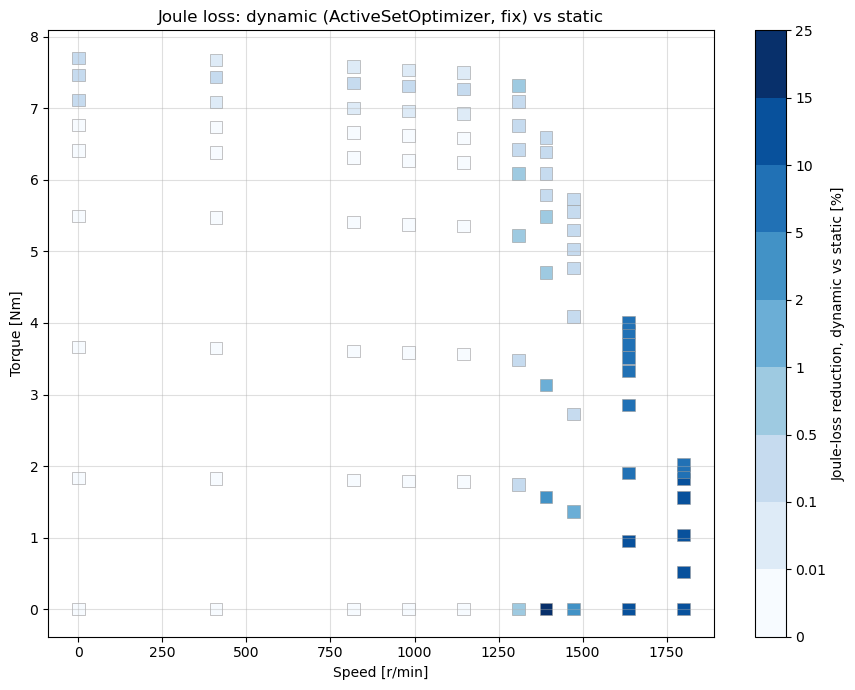

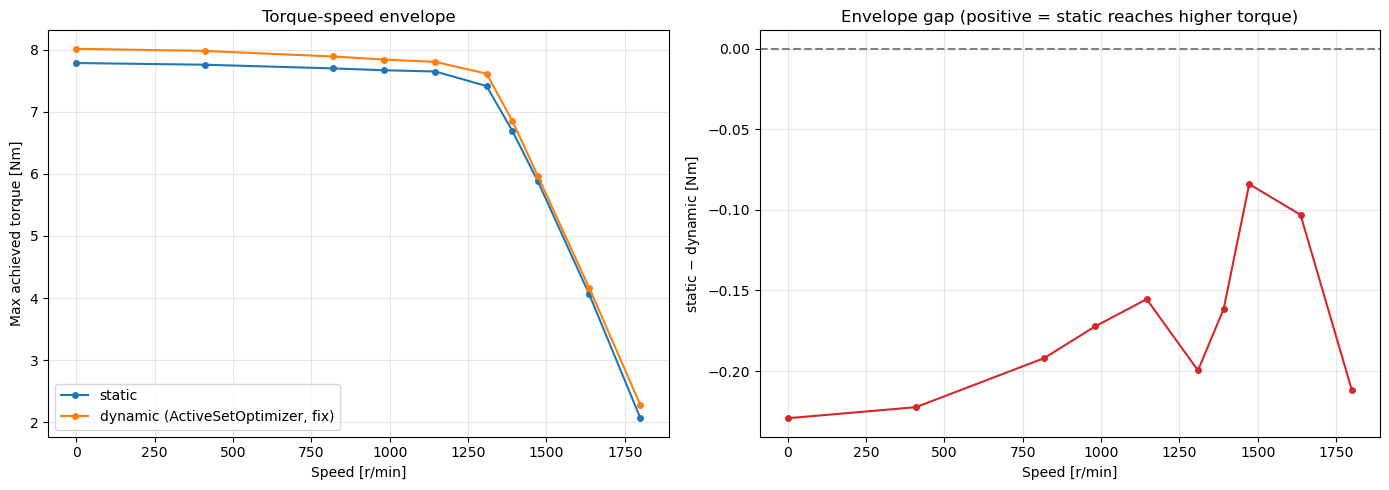

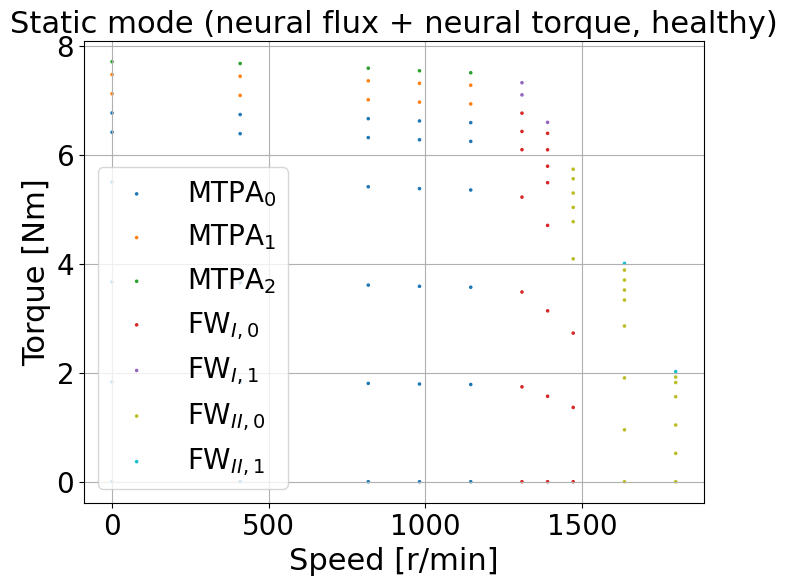

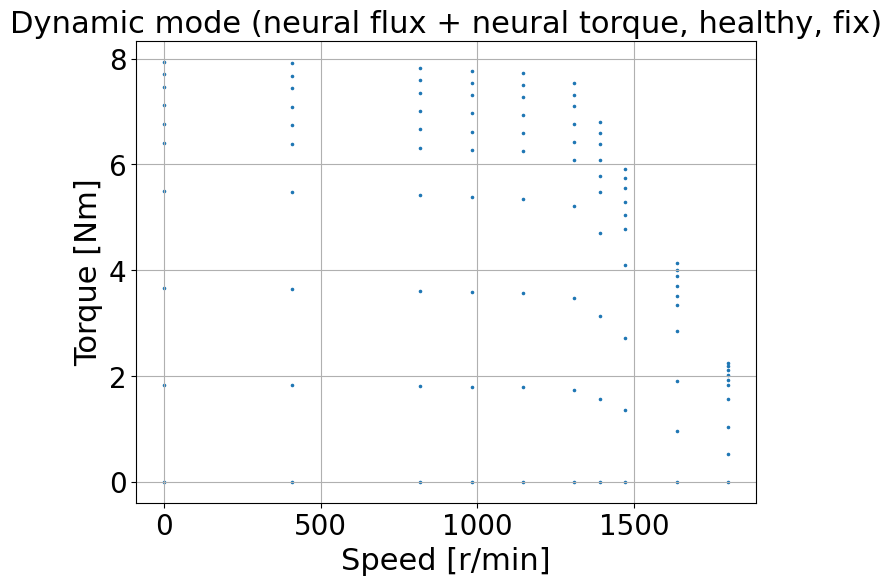

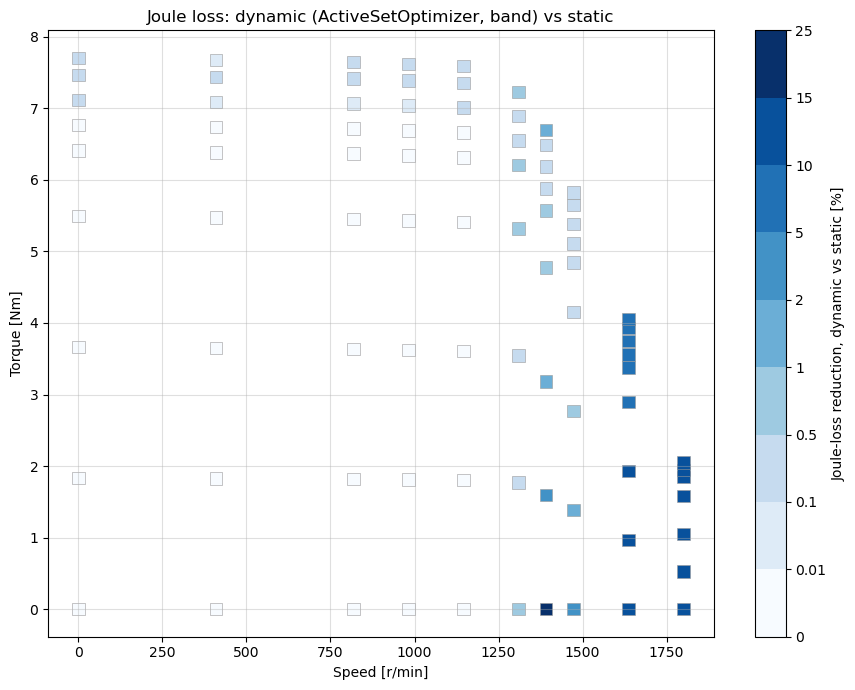

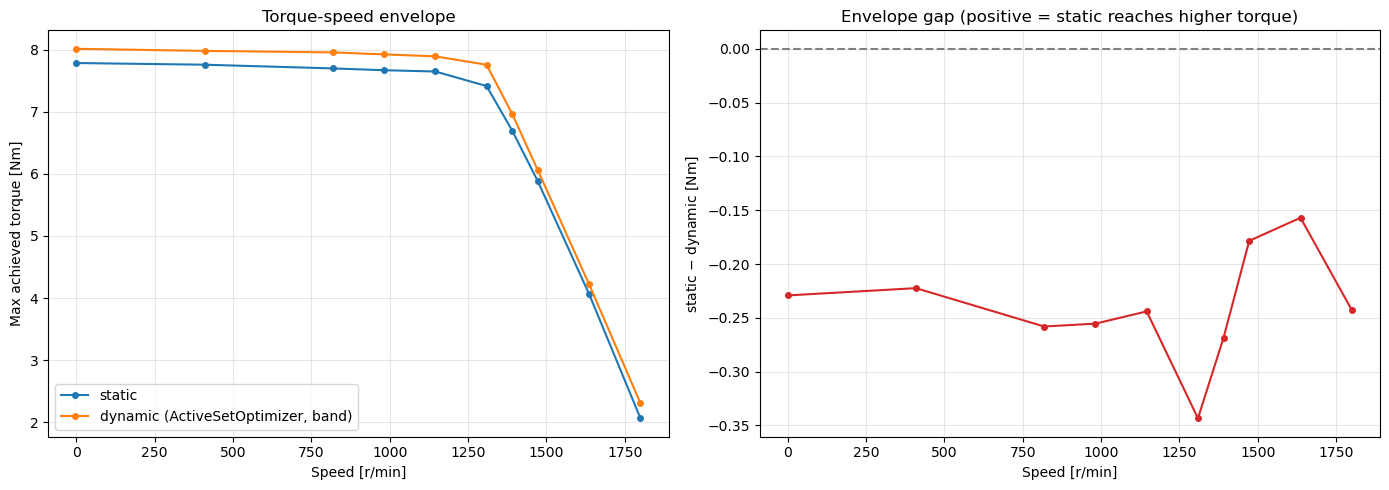

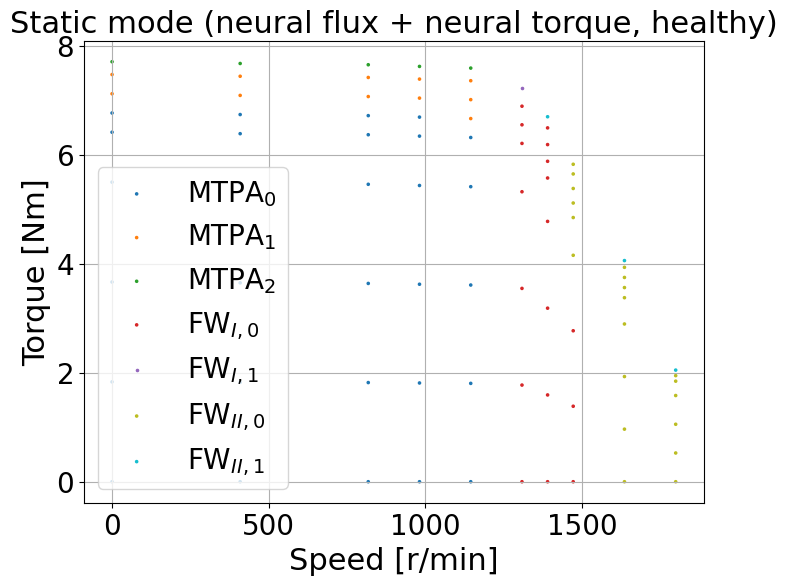

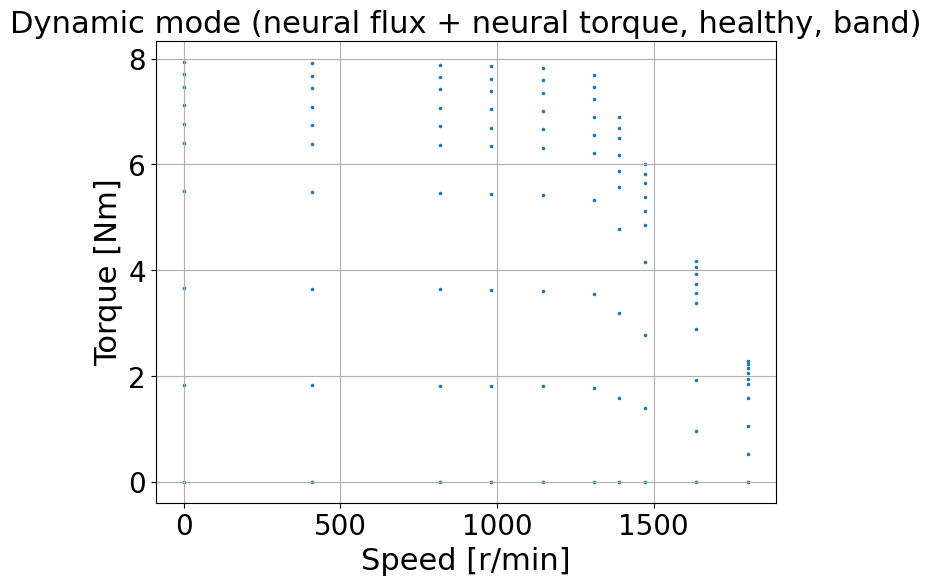

In [6]:
omega_2d = np.broadcast_to(rpm_vec[None, :], (N_TORQ, N_OMEGA))
size = 80 if max(N_TORQ, N_OMEGA) > 10 else 600
for v in VARIANTS:
    r = results[(v, "healthy")]
    if "error" in r:
        print(f"healthy {v}: no results (failed)")
        continue
    summary_dir = os.path.join(figs_dir, f"map_summary_neural_flux_torque_{run_tags[v]}")
    os.makedirs(summary_dir, exist_ok=True)
    torq_2d = r["grid_torq_neural"]
    with np.errstate(divide="ignore", invalid="ignore"):
        joule_pct = 100.0 * (r["dynamic"]["grid_joule_loss"] - r["static"]["grid_joule_loss"]) / r["static"]["grid_joule_loss"]
    both = np.isfinite(joule_pct)
    pct = joule_pct[both]
    fig, ax = plt.subplots(figsize=(9, 7))
    if np.any(both) and np.nanmax(pct) <= 0.01:
        reduction = np.clip(-pct, 0.0, None)
        bounds = [0, 0.01, 0.1, 0.5, 1, 2, 5, 10, 15, max(25, int(np.ceil(reduction.max())))]
        cmap = plt.get_cmap("Blues", len(bounds) - 1)
        sc = ax.scatter(omega_2d[both], torq_2d[both], c=reduction, cmap=cmap, norm=BoundaryNorm(bounds, cmap.N),
                        s=size, marker="s", edgecolors="0.6", linewidths=0.4)
        cbar = fig.colorbar(sc, ax=ax, ticks=bounds, spacing="uniform", label="Joule-loss reduction, dynamic vs static [%]")
        cbar.ax.set_yticklabels([f"{b:g}" for b in bounds])
    else:
        vmax = max(float(np.nanmax(np.abs(pct))), 0.1) if np.any(both) else 1.0
        sc = ax.scatter(omega_2d[both], torq_2d[both], c=pct, cmap="RdBu_r",
                        norm=SymLogNorm(linthresh=0.01, linscale=0.5, vmin=-vmax, vmax=vmax, base=10),
                        s=size, marker="s", edgecolors="0.6", linewidths=0.4)
        fig.colorbar(sc, ax=ax, label="Joule loss: (dynamic $-$ static) / static [%]")
    ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]")
    ax.set_title(f"Joule loss: dynamic (ActiveSetOptimizer, {v}) vs static")
    ax.grid(True, alpha=0.4)
    plt.tight_layout(); fig.savefig(os.path.join(summary_dir, "joule_loss_dynamic_vs_static.png"), dpi=130); plt.show()

    p = r["probe"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(rpm_vec, p["tmax_static_row"], "o-", ms=4, label="static", color="tab:blue")
    ax1.plot(rpm_vec, p["tmax_old_row"], "o-", ms=4, label=f"dynamic (ActiveSetOptimizer, {v})", color="tab:orange")
    ax1.set_xlabel("Speed [r/min]"); ax1.set_ylabel("Max achieved torque [Nm]")
    ax1.set_title("Torque-speed envelope"); ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(rpm_vec, p["tmax_static_row"] - p["tmax_old_row"], "o-", ms=4, color="tab:red")
    ax2.axhline(0.0, color="gray", ls="--")
    ax2.set_xlabel("Speed [r/min]"); ax2.set_ylabel("static $-$ dynamic [Nm]")
    ax2.set_title("Envelope gap (positive = static reaches higher torque)"); ax2.grid(alpha=0.3)
    plt.tight_layout(); fig.savefig(os.path.join(summary_dir, "envelope_static_vs_dynamic.png"), dpi=130); plt.show()

    _show = plt.show
    plt.show = lambda *a, _p=os.path.join(summary_dir, "region_map_static.png"), **k: (plt.gcf().savefig(_p, dpi=130), _show(*a, **k))
    try:
        plot_grid_segments(grid_to_data(r["static"], k_skip=1), title="Static mode (neural flux + neural torque, healthy)",
                           override_torq_2d=torq_2d)
    finally:
        plt.show = _show
    solved_dyn = np.isfinite(r["dynamic"]["grid_joule_loss"])
    with plt.rc_context(PlotConfig.get_rc_params()):
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.set_title(f"Dynamic mode (neural flux + neural torque, healthy, {v})")
        ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]")
        ax.scatter(omega_2d[solved_dyn], torq_2d[solved_dyn], s=10, c="tab:blue", marker=".")
        ax.grid(True)
        fig.savefig(os.path.join(summary_dir, "solved_points_dynamic.png"), dpi=130)
        plt.show()

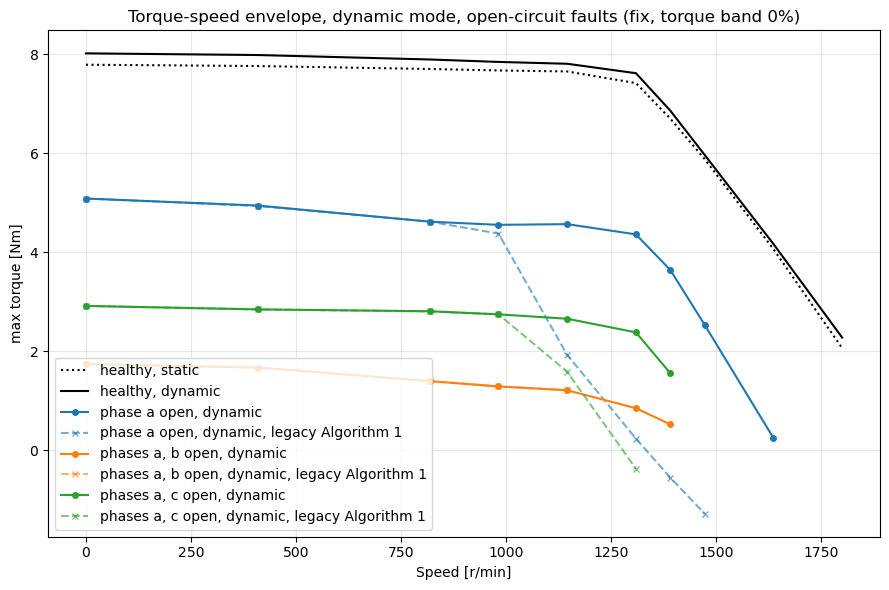

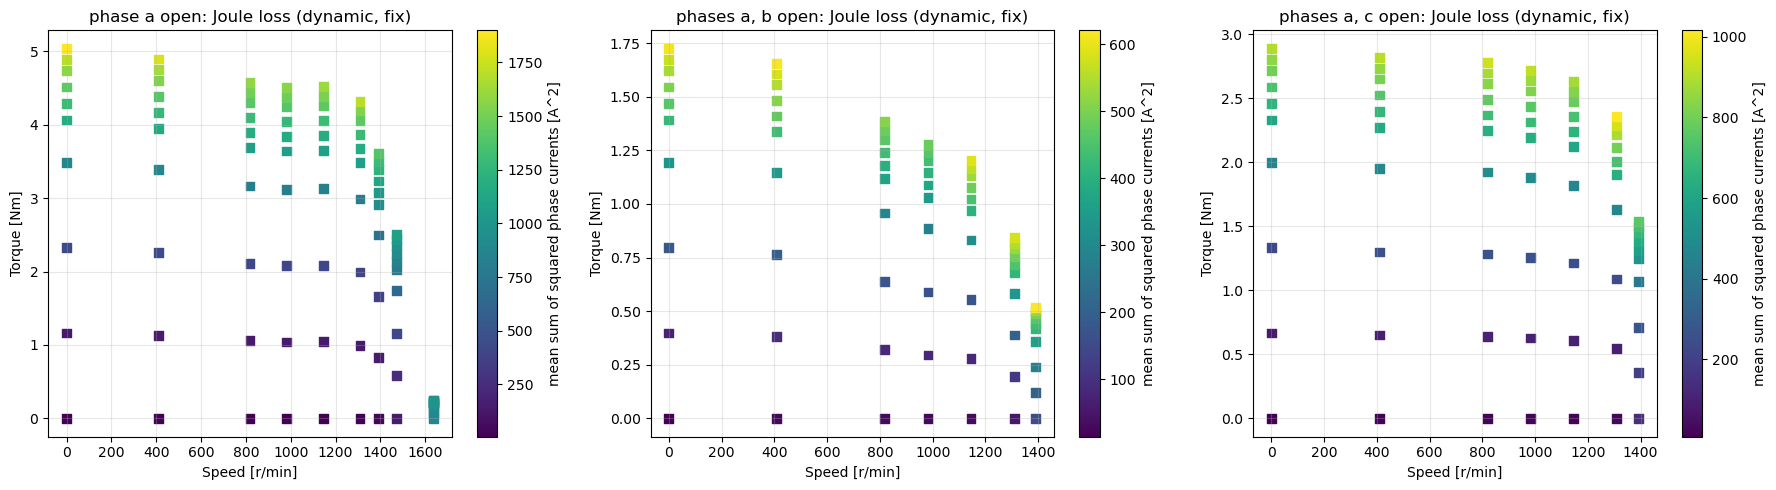

limit check over the solved cells, fix (nodes and both segment ends):
  one_fault       : 90 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.001 V (limit 13.0)
  two_adjacent    : 70 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0)
  two_nonadjacent : 70 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.001 V (limit 13.0)


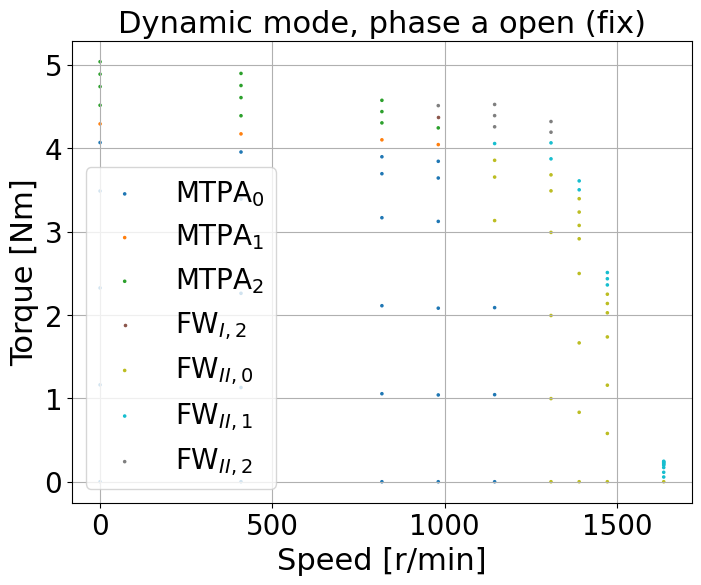

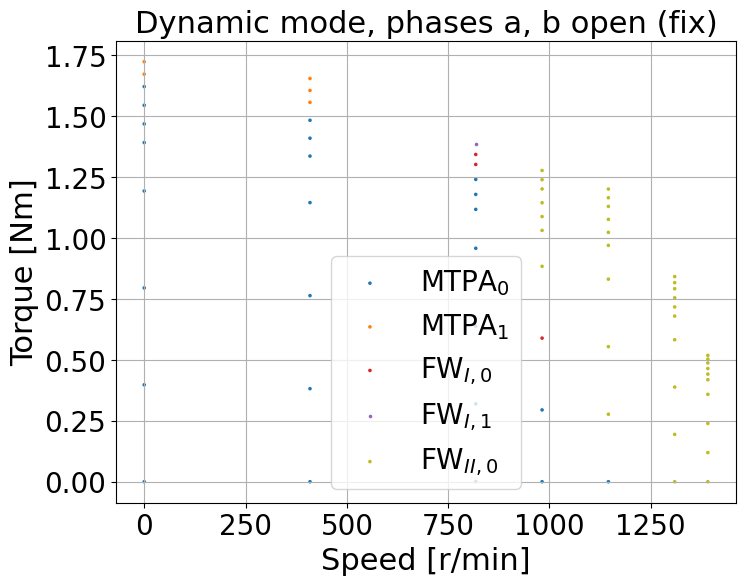

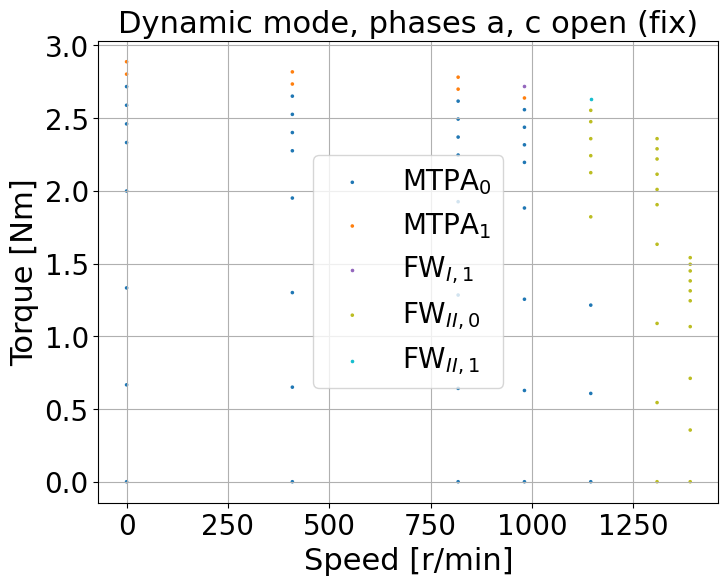

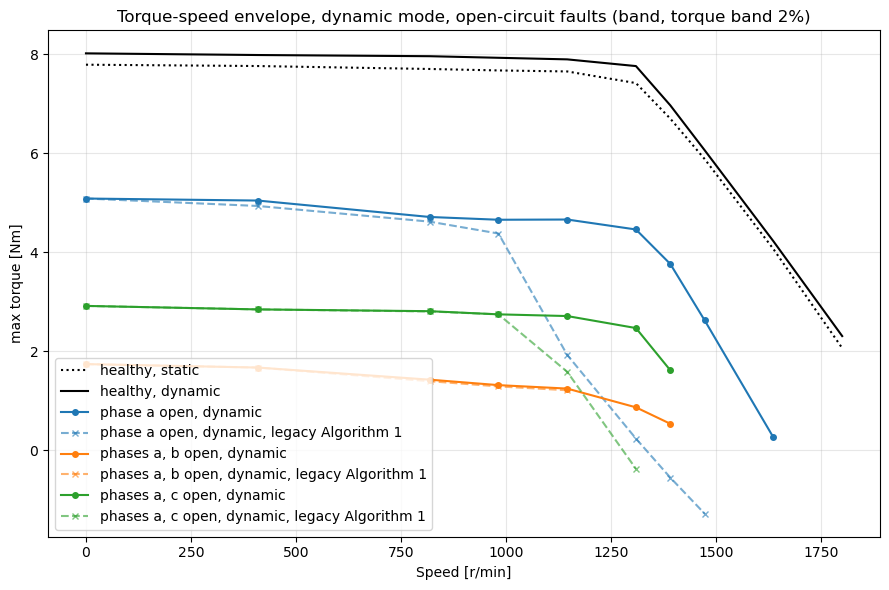

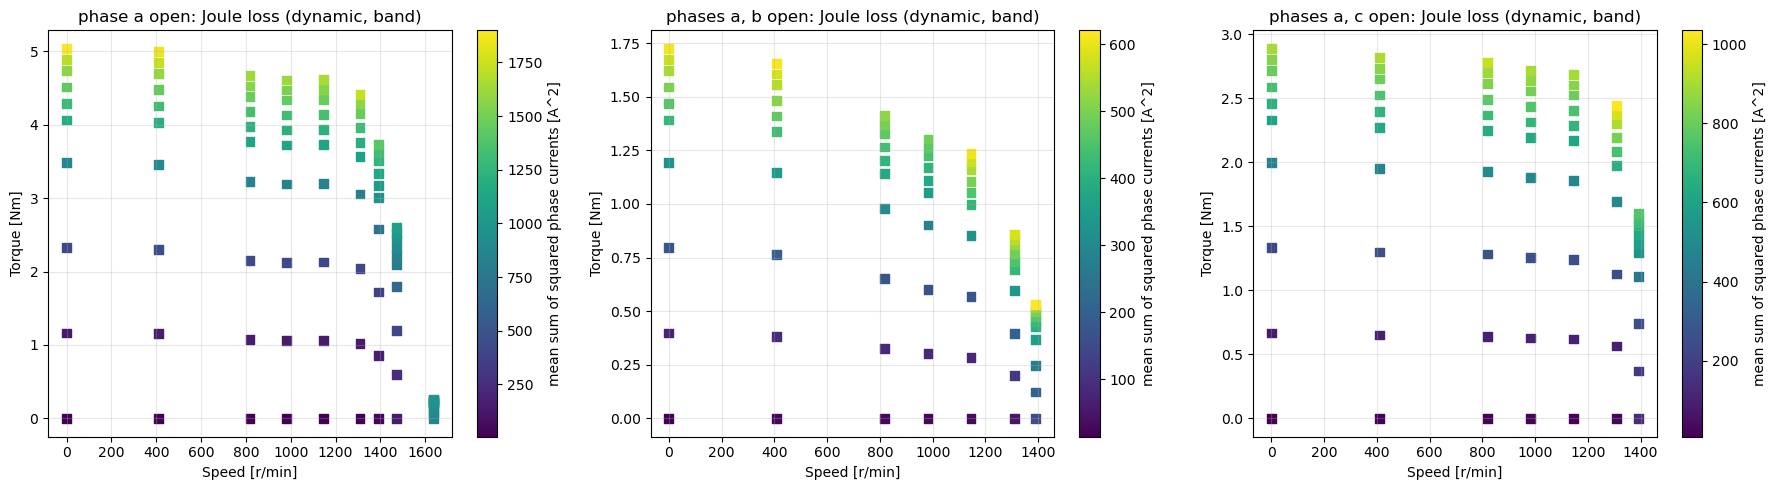

limit check over the solved cells, band (nodes and both segment ends):
  one_fault       : 90 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.001 V (limit 13.0)
  two_adjacent    : 70 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0)
  two_nonadjacent : 70 cells solved, peak phase current 30.000 A (limit 30.0), peak phase voltage 13.000 V (limit 13.0)


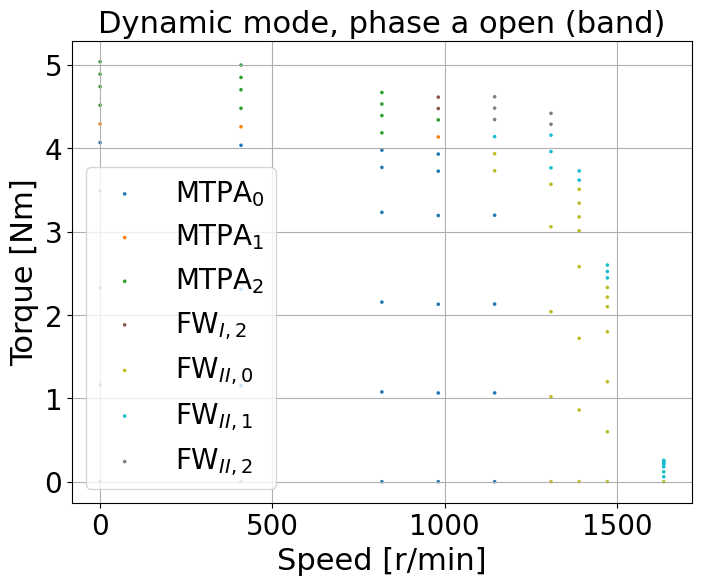

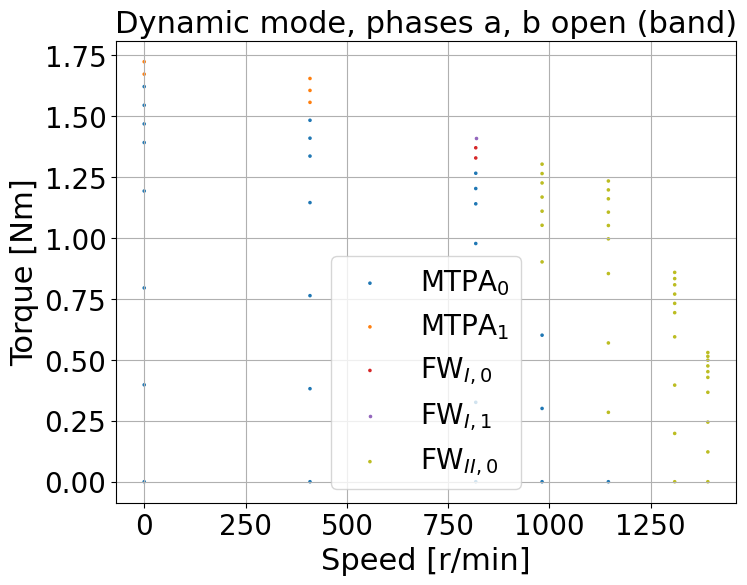

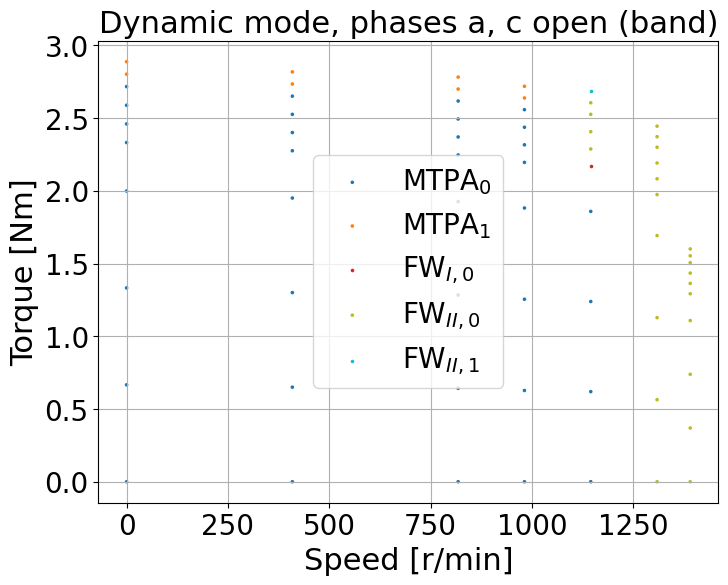

In [7]:
for v in VARIANTS:
    summary_dir = os.path.join(figs_dir, f"fault_maps_dynamic_summary_{run_tags[v]}")
    os.makedirs(summary_dir, exist_ok=True)
    fres = {c: results[(v, c)] for c in FAULTS if "error" not in results[(v, c)]}
    for c in FAULTS:
        if c not in fres:
            print(f"{c} {v}: no results (failed)")

    fig, ax = plt.subplots(figsize=(9, 6))
    hr = results[(v, "healthy")]
    if "error" not in hr:
        ax.plot(rpm_vec, hr["probe"]["tmax_static_row"], "k:", label="healthy, static")
        ax.plot(rpm_vec, hr["probe"]["tmax_old_row"], "k-", label="healthy, dynamic")
    for c, grid in fres.items():
        line, = ax.plot(rpm_vec, grid["probe_tmax"], "o-", ms=4, label=f"{CASE_TITLES[c]}, dynamic")
        legacy_pkl = os.path.join(data_dir, f"fault_map_dynamic_{c}_{LEGACY_TAG}.pkl")
        if os.path.isfile(legacy_pkl) and not QUICK:
            with open(legacy_pkl, "rb") as f:
                legacy_tmax = pickle.load(f)["probe_tmax"]
            if len(legacy_tmax) == FULL_N:
                ax.plot(rpm_vec, np.asarray(legacy_tmax)[SPEED_IDX], "x--", ms=4, color=line.get_color(), alpha=0.6,
                        label=f"{CASE_TITLES[c]}, dynamic, legacy Algorithm 1")
    ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("max torque [Nm]"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title(f"Torque-speed envelope, dynamic mode, open-circuit faults ({v}, torque band {VARIANTS[v]:.0%})")
    fig.tight_layout(); fig.savefig(os.path.join(summary_dir, "envelopes.png"), dpi=130); plt.show()

    if fres:
        fig, axs = plt.subplots(1, len(fres), figsize=(6 * len(fres), 5), squeeze=False)
        for ax, (c, grid) in zip(axs[0], fres.items()):
            T2 = grid["grid_torq_neural"]
            O2 = np.broadcast_to(rpm_vec[None, :], T2.shape)
            ok = np.isfinite(grid["grid_joule_loss"])
            sc = ax.scatter(O2[ok], T2[ok], c=grid["grid_joule_loss"][ok], cmap="viridis", s=40 if N_TORQ > 10 else 300, marker="s")
            fig.colorbar(sc, ax=ax, label="mean sum of squared phase currents [A^2]")
            ax.set_title(f"{CASE_TITLES[c]}: Joule loss (dynamic, {v})"); ax.set_xlabel("Speed [r/min]"); ax.set_ylabel("Torque [Nm]")
            ax.grid(alpha=0.3)
        fig.tight_layout(); fig.savefig(os.path.join(summary_dir, "joule_loss_maps.png"), dpi=130); plt.show()

    print(f"limit check over the solved cells, {v} (nodes and both segment ends):")
    for c, grid in fres.items():
        ok = np.isfinite(grid["grid_joule_loss"])
        print(f"  {c:16s}: {int(ok.sum())} cells solved, peak phase current {np.nanmax(grid['grid_curr_peak']):.3f} A (limit {CURR_MAX}), "
              f"peak phase voltage {np.nanmax(grid['grid_volt_peak']):.3f} V (limit {VOLT_MAX})")

    _show = plt.show
    try:
        for c, grid in fres.items():
            fpath = os.path.join(summary_dir, f"region_map_dynamic_{c}.png")
            plt.show = lambda *a, _p=fpath, **k: (plt.gcf().savefig(_p, dpi=130, bbox_inches="tight"), _show(*a, **k))
            plot_grid_segments(grid_to_data(grid, k_skip=1), title=f"Dynamic mode, {CASE_TITLES[c]} ({v})",
                               override_torq_2d=grid["grid_torq_neural"])
    finally:
        plt.show = _show